## Step 2: Baseline Models

**Goal:** measure simple and zero-shot systems on the validation split; To be compared with Fine-tuned Models after.

**Task:** given a question, rank all candidate answers and find the correct one.

**Metrics**
- **Recall@k:** the correct answer is in the top k results.
- **MRR:** average of 1/rank of the correct answer (rewards ranking it first).

## 1. Setup
### 1.1 Install rank_bm25
installs `rank_bm25`, which splits documents into tokens ,
Computes term frequency (TF) and inverse document frequency (IDF) And then,
Scores each document based on how well it matches the query.

In [1]:
%pip install -q rank_bm25

Note: you may need to restart the kernel to use updated packages.


### 1.2 Imports and paths
imports the libraries, picks the GPU if available, sets `ROOT` and creates the output folders.

In [2]:
import os, re
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    print("No HF_TOKEN secret found, continuing without it")

import torch
import numpy as np
import pandas as pd
import datasets
import matplotlib.pyplot as plt
from glob import glob
from pathlib import Path
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

# switch off the progress bars
datasets.disable_progress_bars()
from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# project root
ROOT = Path("/kaggle/working/healthcare-qa-assistant")
for folder in ["results/metrics", "results/plots"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

Device: cuda


## 2. Load the validation split
finds `val.csv` (working folder first, then attached inputs) and loads it.

In [3]:
local_val = ROOT / "data/processed/val.csv"
found = [Path(p) for p in glob("/kaggle/input/**/data/processed/val.csv", recursive=True)]

if local_val.exists():
    VAL_PATH = local_val
elif found:
    VAL_PATH = max(found, key=lambda p: p.stat().st_mtime)
else:
    raise FileNotFoundError("val.csv not found. Add the output of Notebook 01 as an input.")

print("Using:", VAL_PATH)
val = pd.read_csv(VAL_PATH)
val = val.rename(columns={"Question": "question", "Answer": "answer"})
print(val.shape, val.columns.tolist())

Using: /kaggle/working/healthcare-qa-assistant/data/processed/val.csv
(1585, 3) ['qtype', 'question', 'answer']


## 3. Build the search task
creates the **corpus** (unique validation answers), the **queries** (validation questions) and **gold** (the position of each question's correct answer).

In [4]:
# Search space = unique answers in the validation split
corpus = val["answer"].drop_duplicates().tolist()
answer_to_id = {a: i for i, a in enumerate(corpus)}
queries = val["question"].tolist()
gold = val["answer"].map(answer_to_id).values   # index of the correct answer for each query
print(len(queries), "queries |", len(corpus), "answers")

1585 queries | 1572 answers


## 4. Evaluation function
ranks the answers for each query and reports Recall@1/5/10 and MRR.

In [5]:
def evaluate(scores, gold, ks=(1, 5, 10)):
    """scores: (n_queries, n_answers). Higher = more similar."""
    ranking = (-scores).argsort(axis=1)  # best answer first
    position = np.array([np.where(ranking[i] == gold[i])[0][0] for i in range(len(gold))]) + 1
    result = {f"Recall@{k}": round(float((position <= k).mean()), 4) for k in ks}
    result["MRR"] = round(float((1 / position).mean()), 4)
    return result

## 5. Baseline 1: BM25
classic keyword matching, no neural network. Text is split with a regex so punctuation does not block matches.

In [6]:
def tokenize(text):
    return re.findall(r"\w+", text.lower())

bm25 = BM25Okapi([tokenize(doc) for doc in corpus])
bm25_scores = np.array([bm25.get_scores(tokenize(q)) for q in queries])

results = {"BM25 (baseline)": evaluate(bm25_scores, gold)}
print(results)

{'BM25 (baseline)': {'Recall@1': 0.6732, 'Recall@5': 0.8877, 'Recall@10': 0.9073, 'MRR': 0.7719}}


## 6. Baseline 2: zero-shot embedding models
each pretrained model turns text into vectors, and the most similar answer (cosine similarity) wins. No fine-tuning.

**Notes:**
- BGE needs its query prefix (added to queries only).
- Models cut long answers at their maximum length (see the truncation table in Notebook 01).

In [7]:
# Baseline 2: zero-shot pretrained embedding models (no fine-tuning)
models = {
    "MiniLM-L6 (zero-shot)": ("sentence-transformers/all-MiniLM-L6-v2", ""),
    "BGE-base (zero-shot)": ("BAAI/bge-base-en-v1.5",
                             "Represent this sentence for searching relevant passages: "),
    "PubMedBERT (zero-shot)": ("NeuML/pubmedbert-base-embeddings", ""),
}

for name, (model_id, query_prefix) in models.items():
    model = SentenceTransformer(model_id, device=device)
    doc_emb = model.encode(corpus, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    q_emb = model.encode([query_prefix + q for q in queries], batch_size=64,
                         normalize_embeddings=True, show_progress_bar=True)
    results[name] = evaluate(q_emb @ doc_emb.T, gold)  # cosine similarity
    print(name, results[name])
    del model
    torch.cuda.empty_cache()

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

MiniLM-L6 (zero-shot) {'Recall@1': 0.7842, 'Recall@5': 0.9369, 'Recall@10': 0.9533, 'MRR': 0.8547}


Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

BGE-base (zero-shot) {'Recall@1': 0.8631, 'Recall@5': 0.9615, 'Recall@10': 0.9678, 'MRR': 0.9077}


Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

PubMedBERT (zero-shot) {'Recall@1': 0.7615, 'Recall@5': 0.9476, 'Recall@10': 0.9653, 'MRR': 0.8468}


## 7. Results
builds the results table, saves it with a plot, and prints the best model by Recall@1.

Best by Recall@1: BGE-base (zero-shot)


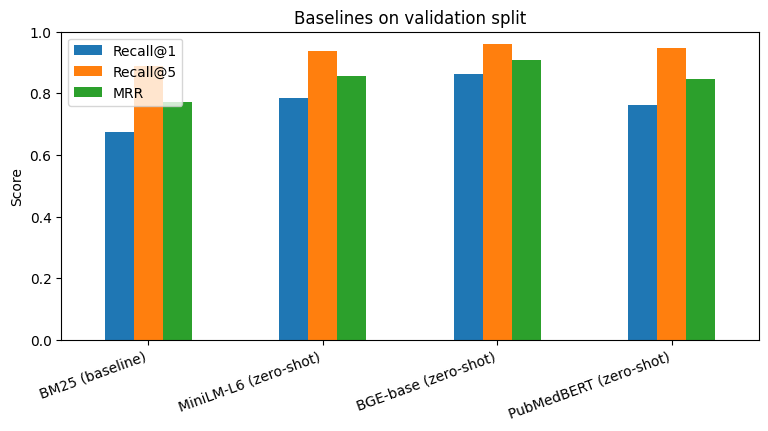

,Recall@1,Recall@5,Recall@10,MRR
BM25 (baseline),0.6732,0.8877,0.9073,0.7719
MiniLM-L6 (zero-shot),0.7842,0.9369,0.9533,0.8547
BGE-base (zero-shot),0.8631,0.9615,0.9678,0.9077
PubMedBERT (zero-shot),0.7615,0.9476,0.9653,0.8468


In [8]:
table = pd.DataFrame(results).T
table.to_csv(ROOT / "results/metrics/baselines.csv")
print("Best by Recall@1:", table["Recall@1"].idxmax())

table[["Recall@1", "Recall@5", "MRR"]].plot(kind="bar", figsize=(9, 4))
plt.title("Baselines on validation split")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.savefig(ROOT / "results/plots/baseline_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

table